<a href="https://colab.research.google.com/github/Rickylel/Clasificacion-de-Gestos-Piedra-Papel-o-Tijera-mediante-Redes-Neuronales-Convolucionales-CNN/blob/main/PIA_INTRO_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de Gestos (Piedra, Papel o Tijera) con Redes Neuronales Convolucionales

**Proyecto Final — Introducción al Aprendizaje Máquina**
Facultad de Ingeniería Mecánica y Eléctrica (FIME), UANL

**Integrantes:**
- Luis Ricardo Salinas De la Peña — 2142924
- Alessandro Galvan Junquera — 2143543
- Peyton Oved Sanchez Olguin — 2152791
- Francisco Gabriel Delgado Ortiz - 2091878

Esta notebook implementa de principio a fin una CNN **construida desde cero** (sin modelos preentrenados) para clasificar imágenes de manos haciendo los gestos de **piedra**, **papel** o **tijera**, usando el dataset público *Rock-Paper-Scissors Images* de Kaggle (`drgfreeman/rockpaperscissors`).

**Contenido**
1. Descarga, carga y preprocesamiento del dataset
2. Diseño y construcción de la arquitectura CNN
3. Entrenamiento, monitoreo y curvas de aprendizaje
4. Análisis avanzado: matriz de confusión, reporte de clasificación y discusión

> **Recomendación:** en Colab activa la GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. El entrenamiento tarda unos pocos minutos con GPU.

## 0. Configuración del entorno

In [ ]:
# En Google Colab casi todo viene instalado; kagglehub sirve para descargar el dataset.
!pip install -q kagglehub

In [ ]:
import os
import random
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---------------- Hiperparámetros y configuración global ----------------
SEED = 42
IMG_HEIGHT, IMG_WIDTH = 150, 150   # resolución uniforme a la que se redimensiona todo
BATCH_SIZE = 32
EPOCHS = 25                        # número fijo de épocas
LEARNING_RATE = 1e-3
CLASSES = ["paper", "rock", "scissors"]          # nombres de carpeta en el dataset
CLASS_NAMES_ES = ["papel", "piedra", "tijera"]   # etiquetas para gráficas y reportes
FIG_DIR = "figuras"                             # aquí se guardan las gráficas para el PDF

# Dataset: nombre del .zip que subes a Colab (panel de archivos 📁 de la izquierda).
# Si el .zip no existe, se descarga automáticamente de Kaggle con kagglehub.
ZIP_PATH = "archive.zip"
EXTRACT_DIR = "dataset"

os.makedirs(FIG_DIR, exist_ok=True)

# Reproducibilidad
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Sección 1. Descarga, carga y preprocesamiento del dataset

### 1.1 Carga del dataset desde un archivo .zip

El dataset **Rock-Paper-Scissors Images** (Julien de la Bruère-Terreault, 2018) contiene **2,188 imágenes** RGB de 300×200 px de manos sobre un fondo verde, repartidas en tres carpetas: `rock` (726), `paper` (712) y `scissors` (750).

La siguiente celda descomprime el `.zip` y localiza sola las carpetas `rock/`, `paper/` y `scissors/`, sin importar cuántas subcarpetas tenga.

In [ ]:
import zipfile

def find_class_root(base_dir, classes=CLASSES):
    # Busca la carpeta que contiene directamente las subcarpetas rock/, paper/ y scissors/.
    for root, dirs, _ in os.walk(base_dir):
        if all(c in dirs for c in classes):
            return root
    raise FileNotFoundError(f"No se encontraron las carpetas {classes} dentro de {base_dir}")

if os.path.exists(ZIP_PATH):
    if not os.path.isdir(EXTRACT_DIR):
        print(f"Descomprimiendo {ZIP_PATH} ...")
        with zipfile.ZipFile(ZIP_PATH) as zf:
            zf.extractall(EXTRACT_DIR)
    DATA_DIR = find_class_root(EXTRACT_DIR)
else:
    print(f"No se encontró '{ZIP_PATH}'; se descargará el dataset desde Kaggle.")
    import kagglehub
    DATA_DIR = find_class_root(kagglehub.dataset_download("drgfreeman/rockpaperscissors"))

print("Carpeta de clases:", DATA_DIR)

Descomprimiendo archive.zip ...
Carpeta de clases: dataset/archive


### 1.2 Carga de rutas y exploración inicial

In [ ]:
EXTS = (".png", ".jpg", ".jpeg")
filepaths, labels = [], []
for idx, cls in enumerate(CLASSES):
    files = sorted(f for f in glob.glob(os.path.join(DATA_DIR, cls, "*")) if f.lower().endswith(EXTS))
    filepaths += files
    labels += [idx] * len(files)

filepaths = np.array(filepaths)
labels = np.array(labels)

df_counts = pd.DataFrame({"clase": [CLASS_NAMES_ES[i] for i in labels]}).value_counts().rename("imágenes").reset_index()
print(f"Total de imágenes: {len(filepaths)}")
df_counts

Total de imágenes: 2188


,clase,imágenes
0,tijera,750
1,piedra,726
2,papel,712


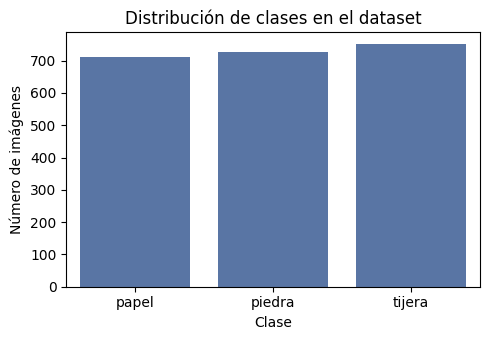

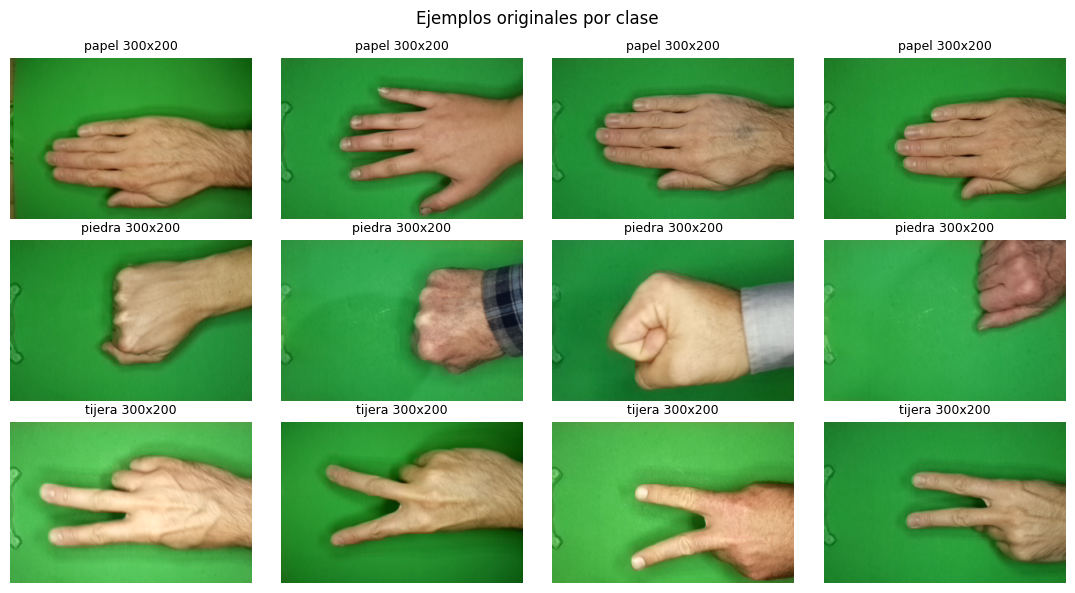

In [ ]:
# Distribución de clases
plt.figure(figsize=(5, 3.5))
sns.countplot(x=[CLASS_NAMES_ES[i] for i in labels], order=CLASS_NAMES_ES, color="#4C72B0")
plt.title("Distribución de clases en el dataset")
plt.xlabel("Clase"); plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/distribucion_clases.png", dpi=150)
plt.show()

# Ejemplos de cada clase en su tamaño original
from PIL import Image
fig, axes = plt.subplots(3, 4, figsize=(11, 6))
for r, cls_idx in enumerate(range(len(CLASSES))):
    samples = np.random.choice(filepaths[labels == cls_idx], 4, replace=False)
    for c, path in enumerate(samples):
        img = Image.open(path)
        axes[r, c].imshow(img)
        axes[r, c].set_title(f"{CLASS_NAMES_ES[cls_idx]} {img.size[0]}x{img.size[1]}", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Ejemplos originales por clase")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ejemplos_dataset.png", dpi=150)
plt.show()

### 1.3 División en entrenamiento, validación y prueba

Se usa una división **estratificada 70 % / 15 % / 15 %** para que las tres clases mantengan la misma proporción en cada conjunto. Los tres conjuntos son independientes: ninguna imagen aparece en más de uno.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    filepaths, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Verificación de que los conjuntos no se traslapan
assert not (set(X_train) & set(X_val) or set(X_train) & set(X_test) or set(X_val) & set(X_test))

split_df = pd.DataFrame({
    name: np.bincount(y, minlength=len(CLASSES))
    for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]
}, index=CLASS_NAMES_ES)
split_df.loc["total"] = split_df.sum()
split_df

,train,validation,test
papel,498,107,107
piedra,508,109,109
tijera,525,112,113
total,1531,328,329


### 1.4 Preprocesamiento: redimensionamiento y normalización

Cada imagen se:
1. lee y decodifica como RGB (3 canales),
2. **redimensiona a 150×150 px**, una resolución uniforme para todas,
3. **normaliza dividiendo entre 255**, llevando los píxeles de [0, 255] a [0, 1].

Las etiquetas se convierten a *one-hot* porque la pérdida `categorical_crossentropy` las requiere así. Se usa `tf.data` para cargar las imágenes por lotes sin llenar la memoria RAM.

In [ ]:
NUM_CLASSES = len(CLASSES)
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])          # redimensionar
    img = tf.cast(img, tf.float32) / 255.0                       # normalizar a [0, 1]
    return img, tf.one_hot(label, NUM_CLASSES)

def make_dataset(paths, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, y))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Comprobación del preprocesamiento
imgs, lbls = next(iter(train_ds))
print("Forma del lote:", imgs.shape, "| etiquetas:", lbls.shape)
print(f"Rango de píxeles tras normalizar: [{imgs.numpy().min():.3f}, {imgs.numpy().max():.3f}]")

Forma del lote: (32, 150, 150, 3) | etiquetas: (32, 3)
Rango de píxeles tras normalizar: [0.000, 1.000]


### 1.5 Pregunta: ¿Por qué normalizar los píxeles a un rango pequeño antes de alimentar la CNN?

1. **Estabilidad numérica del gradiente.** Si la entrada está en [0, 255], las activaciones de la primera capa son cientos de veces más grandes. Eso produce gradientes grandes que hacen que los pesos oscilen o diverjan, o que las funciones de activación se saturen.
2. **Compatibilidad con la inicialización de pesos.** Los inicializadores de Keras (Glorot/He) asumen entradas de magnitud cercana a 1. Con entradas en [0, 1] la varianza de las activaciones se conserva entre capas desde la primera época.
3. **Convergencia más rápida y tasa de aprendizaje razonable.** Con una escala uniforme, la superficie de pérdida está mejor condicionada (menos “alargada”), así que el optimizador (Adam) avanza de forma más directa al mínimo y la misma tasa de aprendizaje sirve para todos los pesos.
4. **Escala homogénea entre imágenes y canales.** Todos los datos quedan en el mismo rango, lo que vuelve el entrenamiento más predecible y reproducible.

En resumen, normalizar no cambia la información de la imagen (solo su escala), pero hace que la optimización sea más estable, rápida y confiable.

## Sección 2. Diseño y construcción de la arquitectura CNN desde cero

Arquitectura secuencial diseñada por el equipo, **sin pesos preentrenados**:

| Bloque | Capas | Propósito |
|---|---|---|
| Aumento de datos | `RandomFlip`, `RandomRotation`, `RandomZoom` | Variaciones de posición de la mano; solo activas al entrenar |
| Conv 1 | `Conv2D(32, 3×3, ReLU)` + `MaxPooling2D(2×2)` | Bordes y texturas simples |
| Conv 2 | `Conv2D(64, 3×3, ReLU)` + `MaxPooling2D(2×2)` | Contornos de dedos |
| Conv 3 | `Conv2D(128, 3×3, ReLU)` + `MaxPooling2D(2×2)` | Partes de la mano |
| Conv 4 | `Conv2D(128, 3×3, ReLU)` + `MaxPooling2D(2×2)` | Forma global del gesto |
| Clasificador | `Flatten` → `Dropout(0.5)` → `Dense(256, ReLU)` → `Dense(3, Softmax)` | Decisión final entre las 3 clases |

El aumento de datos no agrega imágenes nuevas al dataset: transforma aleatoriamente las de entrenamiento en cada época para reducir el sobreajuste. En validación, prueba y predicción esas capas no hacen nada.

In [ ]:
def build_cnn(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), num_classes=NUM_CLASSES):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        # Aumento de datos (solo durante el entrenamiento)
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.1, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),

        # Bloques convolucionales: Conv2D + MaxPooling2D
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        # Clasificador totalmente conectado
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(256, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ], name="CNN_Piedra_Papel_Tijera")
    return model

model = build_cnn()
model.summary()

Model: "CNN_Piedra_Papel_Tijera"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,896,067 (11.05 MB)

 Trainable params: 2,896,067 (11.05 MB)

 Non-trainable params: 0 (0.00 B)

### 2.1 Compilación

- **Optimizador:** Adam (tasa de aprendizaje = 0.001). Ajusta la tasa por parámetro y converge bien sin mucho ajuste manual.
- **Función de pérdida:** `categorical_crossentropy`, la adecuada para clasificación multiclase con salida *softmax* y etiquetas *one-hot*.
- **Métrica:** `accuracy` (precisión global).

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## Sección 3. Entrenamiento, monitoreo y curvas de aprendizaje

Se entrena con **batch size = 32** durante **25 épocas fijas**, monitoreando la pérdida y la precisión en validación al final de cada época.

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1,
)

Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 14s 91ms/step - accuracy: 0.4807 - loss: 1.0205 - val_accuracy: 0.5183 - val_loss: 0.8645
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.8276 - loss: 0.4258 - val_accuracy: 0.9146 - val_loss: 0.2349
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - accuracy: 0.9079 - loss: 0.2482 - val_accuracy: 0.9451 - val_loss: 0.1460
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9203 - loss: 0.2282 - val_accuracy: 0.9207 - val_loss: 0.2238
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.9477 - loss: 0.1519 - val_accuracy: 0.9177 - val_loss: 0.2237
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9549 - loss: 0.1465 - val_accuracy: 0.9482 - val_loss: 0.1543
Epoch 7/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.9556 - loss: 0.1245 - val_accuracy: 0.9451 - val_loss: 0.1447
Epoch 8/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.9406 - loss: 0.1597 - val_accuracy: 0.9726 -

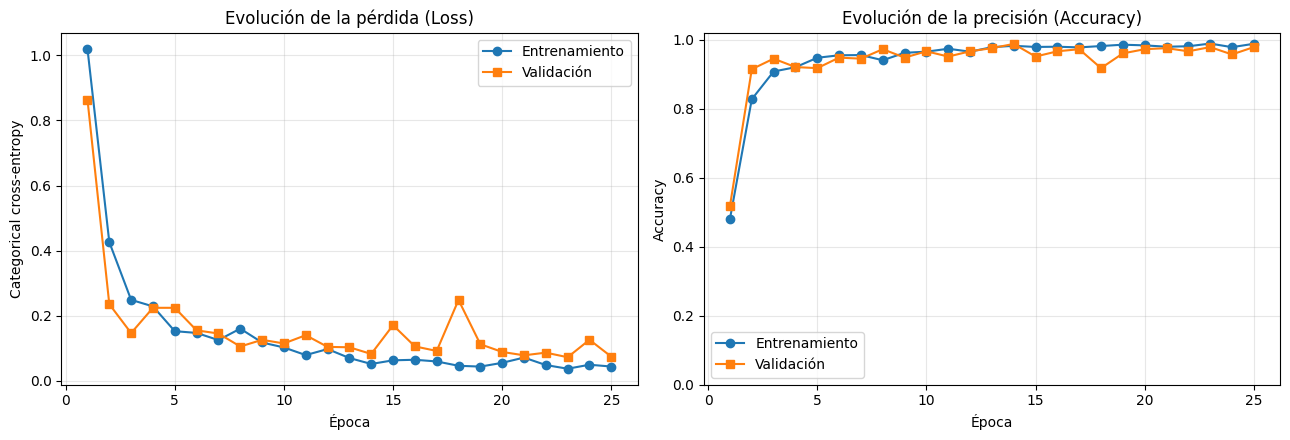

Mejor val_accuracy: 0.9878 (época 14)
Última época -> train_acc: 0.9882 | val_acc: 0.9787


In [ ]:
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
epochs_range = hist.index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs_range, hist["loss"], "o-", label="Entrenamiento")
axes[0].plot(epochs_range, hist["val_loss"], "s-", label="Validación")
axes[0].set_title("Evolución de la pérdida (Loss)")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Categorical cross-entropy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, hist["accuracy"], "o-", label="Entrenamiento")
axes[1].plot(epochs_range, hist["val_accuracy"], "s-", label="Validación")
axes[1].set_title("Evolución de la precisión (Accuracy)")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/curvas_aprendizaje.png", dpi=150)
plt.show()

best = hist["val_accuracy"].idxmax()
print(f"Mejor val_accuracy: {hist['val_accuracy'].max():.4f} (época {best})")
print(f"Última época -> train_acc: {hist['accuracy'].iloc[-1]:.4f} | val_acc: {hist['val_accuracy'].iloc[-1]:.4f}")

### 3.1 Evaluación final sobre el conjunto de prueba

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Pérdida en prueba (Test loss):     {test_loss:.4f}")
print(f"Precisión en prueba (Test accuracy): {test_acc:.4f}  ({test_acc*100:.2f} %)")

# Se guarda el modelo entrenado
model.save("modelo_rps_cnn.keras")

Pérdida en prueba (Test loss):     0.0526
Precisión en prueba (Test accuracy): 0.9818  (98.18 %)


## Sección 4. Análisis avanzado, matriz de confusión y discusión crítica

### 4.1 Matriz de confusión y reporte de clasificación

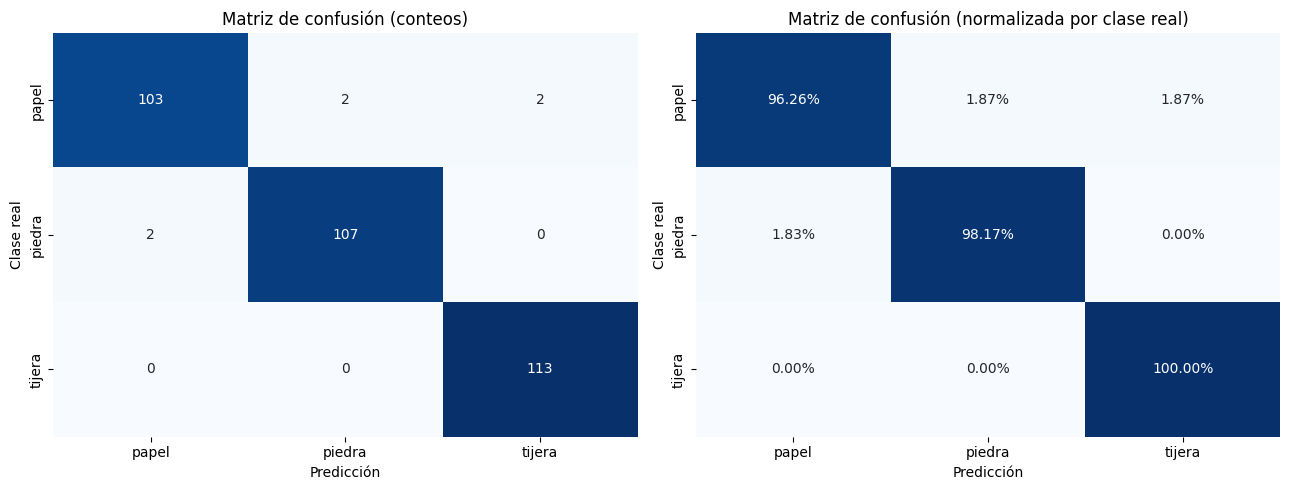

In [ ]:
# Predicciones sobre el conjunto de prueba (el orden de test_ds coincide con X_test/y_test)
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES_ES, yticklabels=CLASS_NAMES_ES, ax=axes[0])
axes[0].set_title("Matriz de confusión (conteos)")
axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Clase real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES_ES, yticklabels=CLASS_NAMES_ES, ax=axes[1])
axes[1].set_title("Matriz de confusión (normalizada por clase real)")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Clase real")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/matriz_confusion.png", dpi=150)
plt.show()

In [ ]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_ES, digits=4))

report_df = pd.DataFrame(
    classification_report(y_true, y_pred, target_names=CLASS_NAMES_ES, output_dict=True)
).T.round(4)
report_df.to_csv(f"{FIG_DIR}/reporte_clasificacion.csv")
report_df

              precision    recall  f1-score   support

       papel     0.9810    0.9626    0.9717       107
      piedra     0.9817    0.9817    0.9817       109
      tijera     0.9826    1.0000    0.9912       113

    accuracy                         0.9818       329
   macro avg     0.9817    0.9814    0.9815       329
weighted avg     0.9818    0.9818    0.9817       329



,precision,recall,f1-score,support
papel,0.9810,0.9626,0.9717,107.0000
piedra,0.9817,0.9817,0.9817,109.0000
tijera,0.9826,1.0000,0.9912,113.0000
accuracy,0.9818,0.9818,0.9818,0.9818
macro avg,0.9817,0.9814,0.9815,329.0000
weighted avg,0.9818,0.9818,0.9817,329.0000


### 4.2 Ejemplos visuales de aciertos y errores

Aciertos: 323 | Errores: 6 | Total prueba: 329


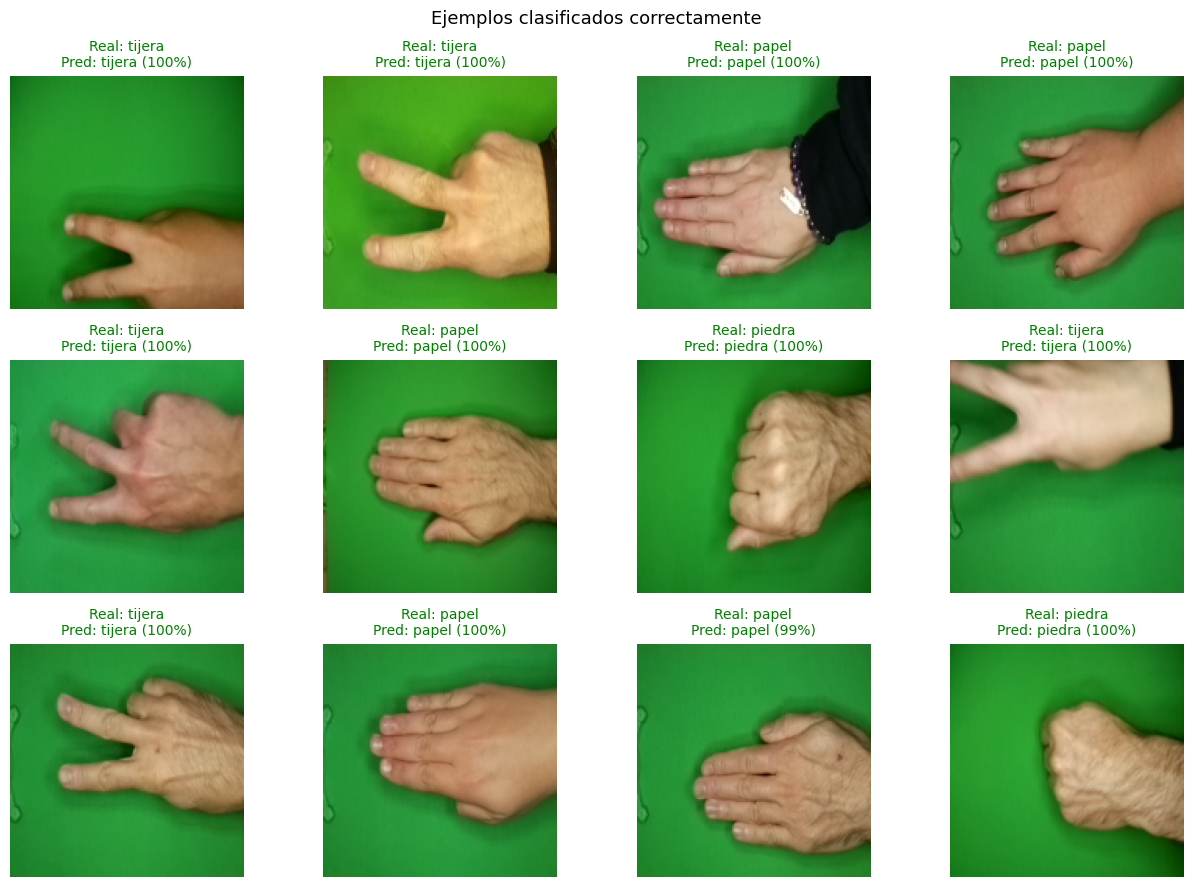

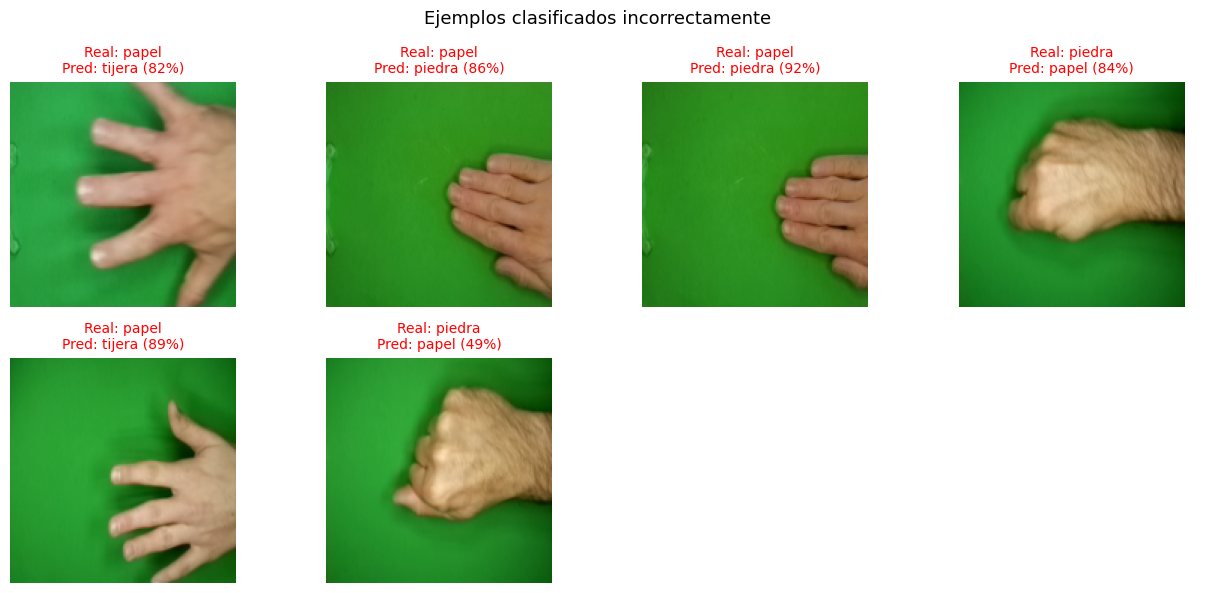

In [ ]:
def show_examples(indices, title, filename, n=12):
    indices = list(indices)[:n]
    if len(indices) == 0:
        print(f"{title}: no hay ejemplos para mostrar.")
        return
    cols = 4
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.0))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        img, _ = load_and_preprocess(X_test[i], y_test[i])
        ax.imshow(img.numpy())
        ok = y_pred[i] == y_true[i]
        ax.set_title(f"Real: {CLASS_NAMES_ES[y_true[i]]}\nPred: {CLASS_NAMES_ES[y_pred[i]]} ({y_prob[i].max():.0%})",
                     color="green" if ok else "red", fontsize=10)
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{filename}", dpi=150)
    plt.show()

rng = np.random.default_rng(SEED)
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]
print(f"Aciertos: {len(correct_idx)} | Errores: {len(wrong_idx)} | Total prueba: {len(y_true)}")

show_examples(rng.permutation(correct_idx), "Ejemplos clasificados correctamente", "ejemplos_aciertos.png")
show_examples(wrong_idx, "Ejemplos clasificados incorrectamente", "ejemplos_errores.png")

### 4.3 Pares de clases más confundidos

La siguiente celda ordena los errores fuera de la diagonal de la matriz de confusión para identificar automáticamente entre qué gestos se equivoca más el modelo. Además muestra el porcentaje de error por clase real.

In [ ]:
pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append({"real": CLASS_NAMES_ES[i], "predicho_como": CLASS_NAMES_ES[j],
                          "errores": int(cm[i, j]), "% de la clase real": round(100 * cm_norm[i, j], 2)})
confusions = pd.DataFrame(pairs, columns=["real", "predicho_como", "errores", "% de la clase real"])
confusions = confusions.sort_values("errores", ascending=False).reset_index(drop=True)

error_rate = pd.Series(100 * (1 - np.diag(cm_norm)), index=CLASS_NAMES_ES, name="% error").round(2)
print("Tasa de error por clase real:")
print(error_rate.to_string(), "\n")
confusions

Tasa de error por clase real:
papel     3.74
piedra    1.83
tijera    0.00 



,real,predicho_como,errores,% de la clase real
0,papel,piedra,2,1.87
1,papel,tijera,2,1.87
2,piedra,papel,2,1.83


### 4.4 Pregunta final de análisis

**¿Entre qué gestos específicos el modelo presentó mayores confusiones o tasas de error, y a qué similitudes visuales o variaciones en la posición de la mano atribuyes este comportamiento?**

**Resultado observado:** el modelo cometió solo **6 errores en las 329 imágenes de prueba** (98.18 % de precisión). Los errores se reparten en tres pares de gestos con **2 errores cada uno**: **papel → piedra** (1.87 % de las imágenes de papel), **papel → tijera** (1.87 %) y **piedra → papel** (1.83 %). La clase con mayor tasa de error fue **papel (3.74 %)**, porque participa en las tres confusiones, mientras que **tijera no tuvo ningún error** (recall de 100 %). No hubo ninguna confusión entre piedra y tijera.

**Interpretación (a partir de las imágenes mal clasificadas de 4.2):**

- **Papel → piedra:** las dos imágenes muestran la mano de lado, con los dedos juntos y pegada al borde derecho de la imagen. Desde ese ángulo la mano abierta forma un bloque compacto muy parecido a la silueta de un puño, y como parte de la mano queda fuera del cuadro, el modelo no alcanza a ver la palma extendida. En ambos casos se equivocó con alta confianza (86 % y 92 %).
- **Papel → tijera:** en los dos casos la mano está abierta pero rotada y cortada por el borde de la imagen, de modo que solo se distinguen con claridad dos o tres dedos separados. Como lo que caracteriza a la tijera es precisamente ver pocos dedos extendidos, el modelo asignó estas imágenes a esa clase.
- **Piedra → papel:** los dos errores corresponden a puños muy cerca de la cámara, que ocupan gran parte de la imagen, y en uno de ellos el pulgar aparece separado del puño. El tamaño de la mano y el pulgar extendido hacen que la silueta se parezca a una mano abierta. En uno de los casos la probabilidad asignada fue de solo 49 %, lo que indica que el modelo estaba indeciso.
- **Orientación y encuadre:** las seis imágenes mal clasificadas tienen en común que la mano aparece rotada, de lado o parcialmente fuera del cuadro. Con alrededor de 1,500 imágenes de entrenamiento, el modelo ve pocos ejemplos de estas posiciones poco comunes. La tijera, en cambio, obtuvo 100 % de recall porque su forma de dos dedos en V se mantiene distintiva en casi cualquier orientación.

**Limitaciones del modelo:** todas las imágenes del dataset se tomaron con un fondo verde uniforme, la misma cámara e iluminación controlada, así que el desempeño probablemente bajaría con fondos reales, otras cámaras o manos de distintas personas en entornos no controlados. Además, reducir las imágenes a 150×150 sacrifica detalles finos de los dedos. Posibles mejoras: más aumento de datos (brillo, contraste, traslaciones), `BatchNormalization`, mayor resolución de entrada y validar con imágenes tomadas por el equipo.

## Resumen de resultados

In [ ]:
summary = pd.DataFrame({
    "Métrica": ["Imágenes (train / val / test)", "Resolución de entrada", "Batch size", "Épocas",
                "Optimizador", "Accuracy final (train)", "Accuracy final (validación)",
                "Loss en prueba", "Accuracy en prueba", "Macro F1 en prueba"],
    "Valor": [f"{len(X_train)} / {len(X_val)} / {len(X_test)}", f"{IMG_HEIGHT}x{IMG_WIDTH}x3", BATCH_SIZE, EPOCHS,
              f"Adam (lr={LEARNING_RATE})", f"{hist['accuracy'].iloc[-1]:.4f}", f"{hist['val_accuracy'].iloc[-1]:.4f}",
              f"{test_loss:.4f}", f"{test_acc:.4f}", f"{report_df.loc['macro avg', 'f1-score']:.4f}"],
})
summary.to_csv(f"{FIG_DIR}/resumen_resultados.csv", index=False)
summary

,Métrica,Valor
0,Imágenes (train / val / test),1531 / 328 / 329
1,Resolución de entrada,150x150x3
2,Batch size,32
3,Épocas,25
4,Optimizador,Adam (lr=0.001)
5,Accuracy final (train),0.9882
6,Accuracy final (validación),0.9787
7,Loss en prueba,0.0526
8,Accuracy en prueba,0.9818
9,Macro F1 en prueba,0.9815
